# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Setup — data and cleaning pipeline

This is copied from `team_notebook.ipynb` (sections 1 and 4) to set up for the questions from this notebook.

In [36]:
import pandas as pd

df = pd.read_csv('../data/walmart_transactions.csv', dtype=str)

decision_log = []

def clean_store_id(df):

    out = df.copy()
    cleaned = (out['store_id']
               .str.strip()
               .str.upper()
               .str.replace(r'^([A-Z]{2})[-_ ]?(\d+)$', r'\1-\2', regex=True))

    decision_log.append({
        'step': 'clean_store_id',
        'decision': "trimmed spaces, uppercased, unified separator to 'XX-###'",
        'rows_touched': int((cleaned != out['store_id']).sum()),
        'rows_dropped': 0,
    })

    out['store_id'] = cleaned
    return out

def drop_duplicates(df):

    out = df.drop_duplicates(keep='first')

    decision_log.append({
        'step': 'drop_duplicates',
        'decision': 'removed exact duplicate rows, kept the first copy',
        'rows_touched': len(df) - len(out),
        'rows_dropped': len(df) - len(out),
    })

    return out

def drop_near_duplicates(df):

    # Same row in every column except transaction_id. Rows with no timestamp are
    # left alone: with the time unknown we cannot say two rows are the same purchase.
    match_cols = [c for c in df.columns if c != 'transaction_id']
    is_copy = df.sort_values('transaction_id').duplicated(subset=match_cols, keep='first')
    is_copy &= df.loc[is_copy.index, 'timestamp'].notna()

    dropped = df.loc[is_copy[is_copy].index, 'transaction_id']
    out = df.drop(index=dropped.index)

    decision_log.append({
        'step': 'drop_near_duplicates',
        'decision': f'dropped rows identical to another row in every column except transaction_id, '
                    f'keeping the lowest ID. The dropped copies have IDs {dropped.min()} to {dropped.max()} '
                    f'(one consecutive block) and differ from the original only by ID, which points to '
                    f're-entered copies. RISK: two shoppers could genuinely have made the same purchase '
                    f'at the same store and second, in which case we undercount by {len(dropped)} rows '
                    f'({len(dropped) / len(df):.2%} of rows). We judge that unlikely and the cleanup defensible.',
        'rows_touched': len(dropped),
        'rows_dropped': len(dropped),
    })

    return out

# The five formats in the raw data
TIMESTAMP_FORMATS = [
    '%Y-%m-%dT%H:%M:%S',
    '%Y-%m-%d %H:%M:%S', 
    '%m/%d/%Y %H:%M',
    '%m-%d-%Y %H:%M:%S',
    '%d-%b-%Y %H:%M',
]

def parse_timestamp(df):

    out = df.copy()
    parsed = pd.Series(pd.NaT, index=out.index, dtype='datetime64[ns]')

    for fmt in TIMESTAMP_FORMATS:
        parsed = parsed.fillna(pd.to_datetime(out['timestamp'], format=fmt, errors='coerce'))

    blank = int(out['timestamp'].isna().sum())
    unparseable = int(parsed.isna().sum()) - blank

    decision_log.append({
        'step': 'parse_timestamp',
        'decision': f'parsed 5 formats to datetime (month-first) - {blank} blank timestamps - {unparseable} unparseable',
        'rows_touched': int(parsed.notna().sum()),
        'rows_dropped': 0,
    })

    out['timestamp'] = parsed
    return out

def clean_price(df):

    out = df.copy()
    has_dollar = out['unit_price'].str.contains('$', regex=False)
    numeric = pd.to_numeric(out['unit_price'].str.replace('$', '', regex=False).str.strip(), errors='coerce')

    unparseable = int(numeric.isna().sum() - out['unit_price'].isna().sum())

    decision_log.append({
        'step': 'clean_price',
        'decision': f"stripped '$' and converted unit_price to float - {unparseable} unparseable",
        'rows_touched': int(has_dollar.sum()),
        'rows_dropped': 0,
    })

    out['unit_price'] = numeric
    return out

CATEGORY_MAP = {
    'alcohol': 'Alcohol',           'alcoholic beverages': 'Alcohol',
    'baby': 'Baby',                 'baby products': 'Baby',
    'breakfast': 'Breakfast',       'breakfast foods': 'Breakfast',
    'electronics': 'Electronics',
    'emergency': 'Emergency',       'emergency supplies': 'Emergency',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'grocery': 'Grocery',           'groceries': 'Grocery',
    'health': 'Health',             'health & wellness': 'Health',
    'household': 'Household',       'household essentials': 'Household',
    'snacks': 'Snacks',
}

def clean_category(df):

    out = df.copy()
    key = out['category'].str.strip().str.lower()
    mapped = key.map(CATEGORY_MAP)

    # A spelling we have not seen is kept as-is
    unmapped = int(mapped.isna().sum() - out['category'].isna().sum())
    mapped = mapped.fillna(out['category'].str.strip())

    decision_log.append({
        'step': 'clean_category',
        'decision': f"merged {out['category'].nunique()} category spellings into {mapped.nunique()} "
                    f"canonical categories - {unmapped} rows with an unmapped spelling",
        'rows_touched': int((mapped != out['category']).sum()),
        'rows_dropped': 0,
    })

    out['category'] = mapped
    return out

def handle_negative_quantity(df):

    out = df.copy()
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')

    negative = out['quantity'] < 0
    out = out[~negative]

    decision_log.append({
        'step': 'handle_negative_quantity',
        'decision': 'dropped rows with quantity < 0 - (if we are trying to analyze purchase behavior, returns are too small to help make decisions, so we can safely drop them)',
        'rows_touched': int(negative.sum()),
        'rows_dropped': int(negative.sum()),
    })

    return out

begin_rows = len(df)

tx = clean_store_id(df)
tx = parse_timestamp(tx)
tx = clean_price(tx)
tx = clean_category(tx)
tx = drop_duplicates(tx)
tx = drop_near_duplicates(tx)
tx = handle_negative_quantity(tx)

end_rows = len(tx)
print(f"Started with {begin_rows:,} rows, ended with {end_rows:,} ({begin_rows - end_rows} removed by cleaning)")

# Orders per store-local calendar day; used by the Q1 chart and the Q3 join
daily_orders = (tx.dropna(subset=['timestamp'])
                  .assign(date=lambda d: d['timestamp'].dt.normalize())
                  .groupby('date').size().rename('orders').reset_index())


Started with 25,562 rows, ended with 25,372 (190 removed by cleaning)


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [37]:
BASELINE = ('2024-09-08', '2024-09-15')
SURGE = ('2024-09-23', '2024-09-25')

orders_by_day = daily_orders.set_index('date')['orders']
baseline_days = orders_by_day.loc[BASELINE[0]:BASELINE[1]]
surge_days = orders_by_day.loc[SURGE[0]:SURGE[1]]
assert len(baseline_days) == 8 and len(surge_days) == 3, 'a window is missing days'

baseline_per_day = baseline_days.mean()
surge_per_day = surge_days.mean()
multiple = surge_per_day / baseline_per_day

print(f'baseline Sept 8-15:  {baseline_per_day:,.1f} orders/day over {len(baseline_days)} days')
print(f'surge    Sept 23-25: {surge_per_day:,.1f} orders/day over {len(surge_days)} days')
print(f'surge vs baseline:   {multiple:.2f}x')

baseline Sept 8-15:  578.4 orders/day over 8 days
surge    Sept 23-25: 1,773.7 orders/day over 3 days
surge vs baseline:   3.07x


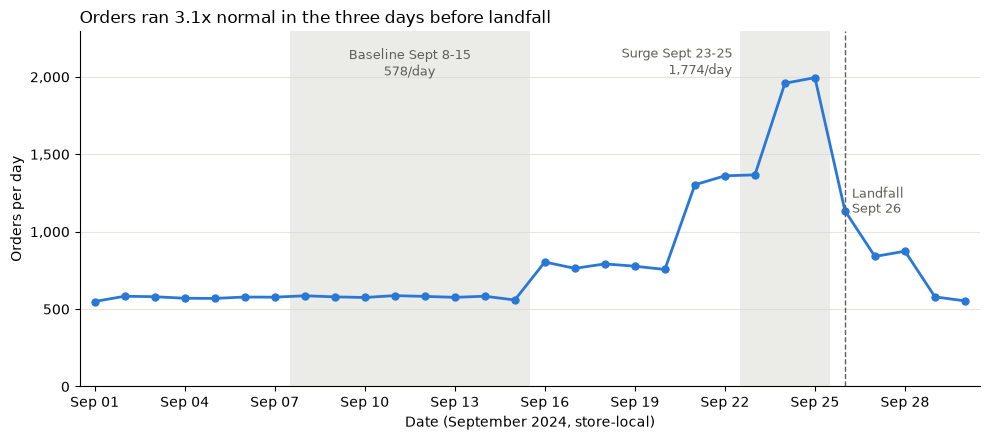

days plotted: 30 (Sep 01 to Sep 30)
zero-order days: []
days with over 10x the median orders: []
peak is 1 day(s) before landfall


In [38]:
# Copied from team_notebook section 5
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

LANDFALL = pd.Timestamp('2024-09-26')

daily = daily_orders.set_index('date')['orders']
all_days = pd.date_range(daily.index.min(), daily.index.max())
daily = daily.reindex(all_days, fill_value=0)

peak_day, peak = daily.idxmax(), daily.max()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily.index, daily.values, color='#2a78d6', lw=2, marker='o', ms=5)

half = pd.Timedelta(hours=12)
for (start, end), label, side in [(BASELINE, f'Baseline Sept 8-15\n{baseline_per_day:,.0f}/day', 'center'),
                                  (SURGE, f'Surge Sept 23-25\n{surge_per_day:,.0f}/day', 'right')]:
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    ax.axvspan(start - half, end + half, color='#d9d8d2', alpha=0.5, lw=0)
    x = start + (end - start) / 2 if side == 'center' else start - half - pd.Timedelta(hours=6)
    ax.annotate(label, (x, peak * 1.1), ha=side, va='top', fontsize=9, color='#5f5f5a')
ax.axvline(LANDFALL, color='#5f5f5a', ls='--', lw=1)
ax.annotate('Landfall\nSept 26', (LANDFALL, peak * 0.6), xytext=(5, 0),
            textcoords='offset points', va='center', fontsize=9, color='#5f5f5a')

ax.set_title(f'Orders ran {multiple:.1f}x normal in the three days before landfall',
             loc='left', fontsize=12)
ax.set_xlabel('Date (September 2024, store-local)')
ax.set_ylabel('Orders per day')
ax.set_ylim(0, peak * 1.15)
ax.set_xlim(daily.index.min() - pd.Timedelta(hours=12), daily.index.max() + pd.Timedelta(hours=12))
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 30, 3)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.grid(axis='y', color='#e6e5e0', lw=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

print('days plotted:', len(daily), f'({daily.index.min():%b %d} to {daily.index.max():%b %d})')
print('zero-order days:', daily.index[daily == 0].strftime('%b %d').tolist())
print('days with over 10x the median orders:', daily.index[daily > 10 * daily.median()].strftime('%b %d').tolist())
lead = (LANDFALL - peak_day).days
print(f'peak is {lead} day(s) before landfall' if lead >= 0 else f'peak is {-lead} day(s) AFTER landfall')

**Q1 answer, in one sentence a manager could read:** In the three days before Helene made landfall (Sep 23–25), our 12 Florida stores averaged 1,774 orders a day, **3.1x** their normal 578 a day (baseline Sept 8–15).

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [39]:
# Copied from team_notebook section 3
SKU_MAP = {
    # Breakfast
    'PT-12':         'Pop-Tarts Strawberry',
    'SKU#459812':    'Pop-Tarts Strawberry',
    'POPTART-STRAW': 'Pop-Tarts Strawberry',
    'PT_STRAWBERRY': 'Pop-Tarts Strawberry',
    # Emergency
    'WTR-24':        'Bottled Water 24-Pack',
    'WATER24PK':     'Bottled Water 24-Pack',
    'WTR_24PK':      'Bottled Water 24-Pack',
    'BATT-100':      'AA Batteries 4-Pack',
    'BAT-AA4':       'AA Batteries 4-Pack',
    'BATT_AA_4PK':   'AA Batteries 4-Pack',
    'FLASH-01':      'LED Flashlight',
    'LED-FLASH':     'LED Flashlight',
    'CNDL-EM':       'Emergency Candles',
    'CANDLE-EMRG':   'Emergency Candles',
    'TARP-HD':       'Heavy Duty Tarp',
    'HDTARP-01':     'Heavy Duty Tarp',
    # Alcohol
    'BEER-24':       'Light Beer 24-Pack',
    'LTBEER24':      'Light Beer 24-Pack',
    # Entertainment
    'BG-MONO':       'Monopoly Board Game',
    'MONOPOLY-01':   'Monopoly Board Game',
    'GAME-MONO':     'Monopoly Board Game',
    'CARDS-01':      'Playing Cards',
    'PLAYCARD-STD':  'Playing Cards',
    # Electronics
    'STREAM-01':     'Roku Streaming Stick',
    'ROKU-STD':      'Roku Streaming Stick',
    'CHRG-PORT':     'Portable Phone Charger',
    'PORTCHARGER':   'Portable Phone Charger',
    # Grocery
    'SOUP-CAN':      'Canned Soup',
    'CNSOUP-01':     'Canned Soup',
    'BREAD-WH':      'White Bread',
    'WHITEBREAD':    'White Bread',
    'PB-16':         'Peanut Butter 16oz',
    'PNUTBTR-16':    'Peanut Butter 16oz',
    # Snacks
    'CHIPS-VP':      'Chips Variety Pack',
    'CHIPVARIETY':   'Chips Variety Pack',
    # Health
    'FAID-01':       'First Aid Kit',
    'FIRSTAID-KIT':  'First Aid Kit',
    # Household
    'PTOWEL-6':      'Paper Towels 6-Roll',
    'PAPERTOWEL6':   'Paper Towels 6-Roll',
    'TP-12':         'Toilet Paper 12-Roll',
    'TOILETPAPER12': 'Toilet Paper 12-Roll',
    # Baby
    'DIAP-S3':       'Diapers Size 3',
    'DIAPERS-3':     'Diapers Size 3',
    'BFORM-01':      'Baby Formula',
    'BABYFORMULA':   'Baby Formula',
}

def consolidate_sku(df):

    out = df.copy()
    out['product'] = out['sku'].str.strip().map(SKU_MAP)
    unmapped = int(out['product'].isna().sum())

    decision_log.append({
        'step': 'consolidate_sku',
        'decision': f"mapped {out['sku'].nunique()} SKUs to {out['product'].nunique()} canonical "
                    f"products with a hand-built SKU_MAP (checked against product_catalog.csv) - "
                    f"{unmapped} unmapped rows. Package sizes in the catalog disagree within a "
                    f"product (e.g. Pop-Tarts 4-pack vs 6 pack) and transactions do not record "
                    f"size, so SKUs of the same product are merged regardless of listed size.",
        'rows_touched': len(out) - unmapped,
        'rows_dropped': 0,
    })

    return out

catalog = pd.read_csv('../data/product_catalog.csv', dtype=str)

# Check every SKU in the data and the catalog is mapped
assert set(tx['sku'].str.strip()) <= SKU_MAP.keys(), set(tx['sku']) - SKU_MAP.keys()
assert set(catalog['sku']) == SKU_MAP.keys()

tx = consolidate_sku(tx)
assert tx['product'].notna().all()

# Check no spelling of product_name lands in two different products
names_per_product = tx.assign(name=tx['product_name'].str.strip()).groupby('name')['product'].nunique()
assert (names_per_product == 1).all(), names_per_product[names_per_product > 1]

groups = tx.groupby('product')['sku'].nunique().sort_values(ascending=False)
print('Distinct SKUs before:', df['sku'].nunique())
print('Canonical products after:', tx['product'].nunique())
print(f'Largest consolidated group: {groups.index[0]} ({groups.iloc[0]} SKUs)')
print()

# Show info of pop tarts
poptarts = tx[tx['product'] == 'Pop-Tarts Strawberry']
display(poptarts.groupby('sku').agg(
    spellings=('product_name', lambda s: sorted(s.str.strip().unique())),
    rows=('sku', 'size'),
    units=('quantity', 'sum'),
))

# Show info on all changess
display(tx.groupby('product').agg(skus=('sku', 'nunique'), rows=('sku', 'size'), units=('quantity', 'sum'))
          .sort_values(['skus', 'units'], ascending=False))

Distinct SKUs before: 45
Canonical products after: 20
Largest consolidated group: Pop-Tarts Strawberry (4 SKUs)



,spellings,rows,units
sku,,,
POPTART-STRAW,"[POPTART-STRAWBERRY, Pop Tarts - Strawberry, P...",502,1298
PT-12,"[POPTART-STRAWBERRY, Pop Tarts - Strawberry, P...",536,1381
PT_STRAWBERRY,"[POPTART-STRAWBERRY, Pop Tarts - Strawberry, P...",512,1262
SKU#459812,"[POPTART-STRAWBERRY, Pop Tarts - Strawberry, P...",502,1255


,skus,rows,units
product,,,
Pop-Tarts Strawberry,4,2052,5196
Bottled Water 24-Pack,3,1485,5224
AA Batteries 4-Pack,3,1451,4296
Monopoly Board Game,3,1332,2015
LED Flashlight,2,1451,2907
Canned Soup,2,1045,2637
Emergency Candles,2,1301,2612
Light Beer 24-Pack,2,1256,2577
Playing Cards,2,1193,2378


unit totals unchanged: 49,535 units before and after consolidation


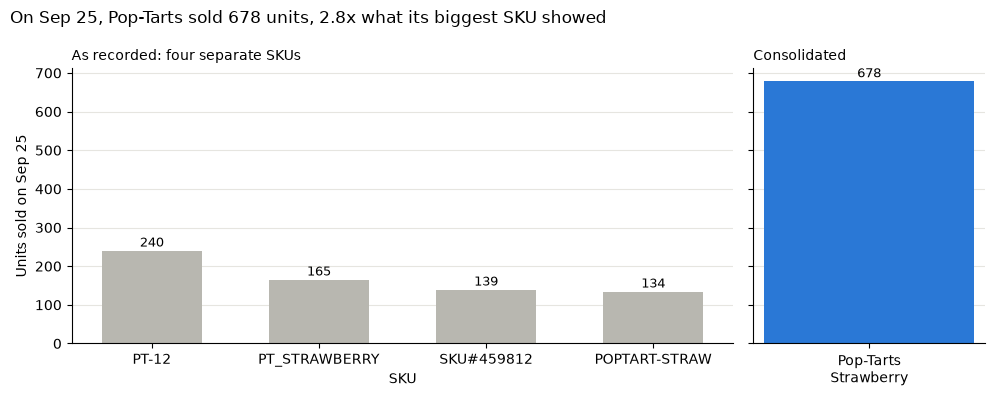

largest single SKU (PT-12) had 35% of Pop-Tarts units on Sep 25

units sold per day in the surge vs the baseline, by product (Sept 23-25 vs Sept 8-15):
product
Pop-Tarts Strawberry      7.21
LED Flashlight            4.20
Bottled Water 24-Pack     4.09
Heavy Duty Tarp           3.81
Monopoly Board Game       3.59
AA Batteries 4-Pack       3.55
Emergency Candles         3.38
Portable Phone Charger    3.34
First Aid Kit             3.13
Roku Streaming Stick      2.98
Light Beer 24-Pack        2.82
Toilet Paper 12-Roll      2.60
Paper Towels 6-Roll       2.59
Playing Cards             2.53
White Bread               2.23
Canned Soup               2.21
Peanut Butter 16oz        2.02
Baby Formula              1.85
Diapers Size 3            1.74
Chips Variety Pack        1.47


In [40]:
# Consolidation must not change any unit totals overall
# And, each product = the sum of its SKUs
units_by_sku = tx.groupby('sku')['quantity'].sum()
units_by_product = tx.groupby('product')['quantity'].sum()
assert units_by_product.sum() == units_by_sku.sum() == tx['quantity'].sum()
assert (units_by_sku.groupby(units_by_sku.index.map(SKU_MAP)).sum() == units_by_product).all()
print(f'unit totals unchanged: {tx["quantity"].sum():,} units before and after consolidation')

# Before and after on the peak day: what a SKU-level report shows vs the real product total
tx['date'] = tx['timestamp'].dt.normalize()
peak_rows = tx[tx['date'] == peak_day]
family = 'Pop-Tarts Strawberry'
fragments = peak_rows[peak_rows['product'] == family].groupby('sku')['quantity'].sum().sort_values(ascending=False)
combined = fragments.sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, gridspec_kw={'width_ratios': [4, 1.4]})
axes[0].bar(fragments.index, fragments.values, color='#b8b7b0', width=0.6)
axes[0].set_title('As recorded: four separate SKUs', loc='left', fontsize=10)
axes[1].bar(['Pop-Tarts\nStrawberry'], [combined], color='#2a78d6', width=0.6)
axes[1].set_title('Consolidated', loc='left', fontsize=10)
for ax, values in [(axes[0], fragments), (axes[1], pd.Series([combined]))]:
    for x, v in enumerate(values):
        ax.annotate(f'{v:,}', (x, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e6e5e0', lw=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel(f'Units sold on {peak_day:%b %d}')
axes[0].set_xlabel('SKU')
fig.suptitle(f'On {peak_day:%b %d}, Pop-Tarts sold {combined:,} units, '
             f'{combined / fragments.max():.1f}x what its biggest SKU showed', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
plt.show()
print(f'largest single SKU ({fragments.index[0]}) had {fragments.max() / combined:.0%} of Pop-Tarts units on {peak_day:%b %d}')

# Surge multiple per consolidated product, same windows as Q1 (units, not orders)
units_daily = tx.groupby(['date', 'product'])['quantity'].sum().unstack(fill_value=0)
product_multiple = (units_daily.loc[SURGE[0]:SURGE[1]].mean()
                    / units_daily.loc[BASELINE[0]:BASELINE[1]].mean()).sort_values(ascending=False)
print('\nunits sold per day in the surge vs the baseline, by product (Sept 23-25 vs Sept 8-15):')
print(product_multiple.round(2).to_string())

**Q2 answer:** The 45 SKUs in the data are really 20 products. The largest group, Pop-Tarts Strawberry, was split across 4 SKUs, so on the peak day (Sept 25) its biggest SKU showed only 240 of the 678 units sold (35%). Consolidated, Pop-Tarts had the biggest surge of any product: **7.2x** its baseline unit sales, against 4.1 for bottled water and flashlights (matches what Prof said in class).

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [41]:
# Copied from team_notebook section 4
import requests, time
import numpy as np

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):

    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError) as err:
            print(f'attempt {attempt}: {type(err).__name__}')
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            print(f'attempt {attempt}: HTTP {r.status_code}, retrying')
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        body = r.json()
        frame = pd.DataFrame(body['daily']).rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])     # string -> datetime right away
        frame['source'] = 'open-meteo'
        frame.attrs['timezone'] = body.get('timezone')
        return frame

start, end = tx['timestamp'].min().date(), tx['timestamp'].max().date()
weather = daily_weather(str(start), str(end))   # live only: fails loudly if the API is down

print('source:', weather['source'].iloc[0], '| timezone:', weather.attrs.get('timezone', 'America/New_York'))
print('weather rows:', len(weather), f'({weather["date"].min():%b %d} to {weather["date"].max():%b %d})')
display(weather)

# Line weather up with sales (daily_orders is built in Setup)

merged = daily_orders.merge(weather, on='date', how='left', indicator=True)
assert len(merged) == len(daily_orders), 'the join changed the row count'
assert merged['orders'].sum() == daily_orders['orders'].sum(), 'the orders total changed'
missing = merged.loc[merged['_merge'] == 'left_only', 'date']
print('sales days:', len(daily_orders), '| matched to weather:', (merged['_merge'] == 'both').sum(),
      '| sales days with no weather:', missing.dt.date.tolist())
print('transactions with no timestamp (left out of the daily counts):', int(tx['timestamp'].isna().sum()))
display(merged.drop(columns='_merge').head())

source: open-meteo | timezone: America/New_York
weather rows: 30 (Sep 01 to Sep 30)


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.9,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,23.1,15.2,open-meteo
5,2024-09-06,9.3,9.0,open-meteo
6,2024-09-07,6.8,14.2,open-meteo
7,2024-09-08,94.7,12.6,open-meteo
8,2024-09-09,28.0,11.5,open-meteo
9,2024-09-10,14.4,14.3,open-meteo


sales days: 30 | matched to weather: 30 | sales days with no weather: []
transactions with no timestamp (left out of the daily counts): 881


,date,orders,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,549,3.0,18.8,open-meteo
1,2024-09-02,583,12.4,13.5,open-meteo
2,2024-09-03,580,24.9,22.8,open-meteo
3,2024-09-04,570,22.1,15.5,open-meteo
4,2024-09-05,569,23.1,15.2,open-meteo


days before the join: 30 | after: 30 | none lost: True
weather source: ['open-meteo']

same day: orders vs max wind r = 0.39 (n = 30 days)
same day: orders vs rain     r = -0.25 (n = 30 days)

each day's orders vs the max wind k days later (k = 0 is the same day):
  k = 0:  r = 0.39  (n = 30 days)
  k = 1:  r = 0.71  (n = 29 days)
  k = 2:  r = 0.82  (n = 28 days)
  k = 3:  r = 0.68  (n = 27 days)
  k = 4:  r = 0.45  (n = 26 days)

orders vs wind 2 days later, leaving out the storm week Sept 21-28: r = 0.09 (n = 20 days)
same comparison on ranks instead of raw values (so the peak days count less): r = 0.40 (n = 28 days)


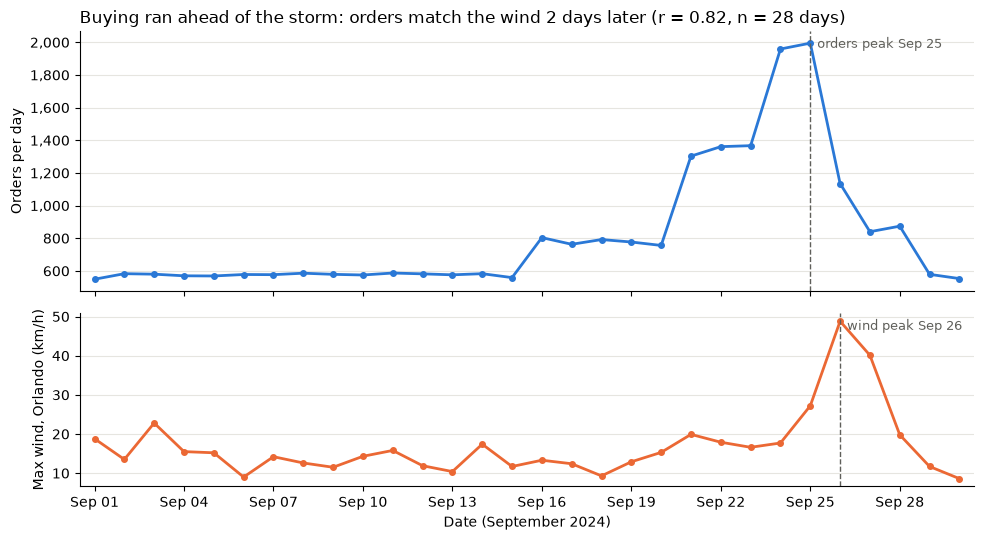

In [42]:
print('days before the join:', len(daily_orders), '| after:', len(merged), '| none lost:', len(merged) == len(daily_orders))
print('weather source:', merged['source'].unique().tolist())

both = merged[merged['_merge'] == 'both']
r_same = both['orders'].corr(both['windspeed_10m_max'])
print(f'\nsame day: orders vs max wind r = {r_same:.2f} (n = {len(both)} days)')
print(f'same day: orders vs rain     r = {both["orders"].corr(both["precipitation_sum"]):.2f} (n = {len(both)} days)')

print("\neach day's orders vs the max wind k days later (k = 0 is the same day):")
lags = {}
for k in range(5):
    wind_later = both['windspeed_10m_max'].shift(-k)
    lags[k] = (both['orders'].corr(wind_later), int(wind_later.notna().sum()))
    print(f'  k = {k}:  r = {lags[k][0]:.2f}  (n = {lags[k][1]} days)')
best_k = max(lags, key=lambda k: lags[k][0])
r_best, n_best = lags[best_k]

wind_best = both['windspeed_10m_max'].shift(-best_k)
calm = ~both['date'].between('2024-09-21', '2024-09-28') & wind_best.notna()
r_calm = both.loc[calm, 'orders'].corr(wind_best[calm])
ok = wind_best.notna()
r_rank = both.loc[ok, 'orders'].rank().corr(wind_best[ok].rank())
print(f'\norders vs wind {best_k} days later, leaving out the storm week Sept 21-28: r = {r_calm:.2f} (n = {int(calm.sum())} days)')
print(f'same comparison on ranks instead of raw values (so the peak days count less): r = {r_rank:.2f} (n = {int(ok.sum())} days)')

# Chart
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
ax1.plot(both['date'], both['orders'], color='#2a78d6', lw=2, marker='o', ms=4)
ax1.set_ylabel('Orders per day')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax2.plot(both['date'], both['windspeed_10m_max'], color='#eb6834', lw=2, marker='o', ms=4)
ax2.set_ylabel('Max wind, Orlando (km/h)')
ax2.set_xlabel('Date (September 2024)')
order_peak = both.loc[both['orders'].idxmax(), 'date']
wind_peak = both.loc[both['windspeed_10m_max'].idxmax(), 'date']
for ax, when, text in [(ax1, order_peak, f'orders peak {order_peak:%b %d}'), (ax2, wind_peak, f'wind peak {wind_peak:%b %d}')]:
    ax.axvline(when, color='#5f5f5a', ls='--', lw=1)
    ax.annotate(text, (when, 1), xycoords=('data', 'axes fraction'), xytext=(5, -4),
                textcoords='offset points', ha='left', va='top', fontsize=9, color='#5f5f5a')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e6e5e0', lw=0.8)
    ax.set_axisbelow(True)
ax2.set_xlim(both['date'].min() - pd.Timedelta(hours=12), both['date'].max() + pd.Timedelta(hours=12))
ax2.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 30, 3)))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax1.set_title(f'Buying ran ahead of the storm: orders match the wind {best_k} days later '
              f'(r = {r_best:.2f}, n = {n_best} days)', loc='left', fontsize=12)
fig.tight_layout()
plt.show()

**Q3 answer, with its caveat:** Shoppers clearly bought ahead of the storm. Daily orders line up best with the wind, and 2 days later, r = 0.82 over 28 days, instead of r = 0.39 for the same day (n = 30). Orders peaked Sep 25 and the wind peaked Sep 26–27. Rain shows no positive relationship (r = −0.25). 

**Caveat:** this is one storm, so its a n = 1 event. Without the storm week (Sep 21–28) the lag-2 correlation drops to r = 0.09 (n = 20), and the rank correlation is 0.40. A manager should analyze it as "buying ran about two days ahead of this storm," and not to look too deeply and think that this happens every time the wind picks up.

Also, the daily order counts leave out the 881 transactions with no timestamp.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

In [43]:
# Quick store-level look, same windows as Q1 (orders per day per store)
store_daily = tx.dropna(subset=['timestamp']).groupby(['date', 'store_id']).size().unstack(fill_value=0)
by_store = pd.DataFrame({
    'baseline_per_day': store_daily.loc[BASELINE[0]:BASELINE[1]].mean(),
    'surge_per_day': store_daily.loc[SURGE[0]:SURGE[1]].mean(),
    'transactions': tx.groupby('store_id').size(),
})
by_store['multiple'] = by_store['surge_per_day'] / by_store['baseline_per_day']
stores = pd.read_csv('../data/store_locations.csv', dtype=str)
stores['store_id'] = (stores['store_id'].str.strip().str.upper()
                      .str.replace(r'^([A-Z]{2})[-_ ]?(\d+)$', r'\1-\2', regex=True))
by_store = stores.drop_duplicates('store_id').set_index('store_id')[['city']].join(by_store, how='right')
display(by_store.sort_values('multiple').round(2))
print(f"store multiples range {by_store['multiple'].min():.2f}x to {by_store['multiple'].max():.2f}x "
      f"across {len(by_store)} stores")

,city,baseline_per_day,surge_per_day,transactions,multiple
store_id,,,,,
FL-239,Orlando,49.38,134.67,2081,2.73
FL-078,Gainesville,50.12,143.67,2066,2.87
FL-501,Fort Myers,50.00,143.33,2061,2.87
FL-412,Jacksonville,48.12,143.67,2100,2.99
FL-156,Daytona Beach,48.50,149.33,2160,3.08
FL-105,Tampa,47.88,148.00,2121,3.09
FL-287,Kissimmee,46.62,144.33,2121,3.10
FL-445,St. Petersburg,48.38,151.33,2164,3.13
FL-619,Tallahassee,44.75,142.00,2050,3.17


store multiples range 2.73x to 3.30x across 12 stores


**Q4 (stores and geography):** In progress. We found that all 12 stores surge by a similar amount. But still to do: find distance from each store to the landfall point, and per-store weather from `daily_weather(lat, lon)`, which needs coordinates for Tallahassee (FL-619). **Owner: Turan**

**Q5 (signal or artifact):** Also started. The surge appears at every store and still shows up after we did our duplicate and near-duplicate removal. Still to do: more investigation into the 881 rows with no timestamp, and how we can use that data to inform decisions or if that just doesn't help up much at all. **Owner: Turan & Danny Checks**

### Self-check

In [44]:
progress = {
    'q1_multiple': round(multiple, 2),   # 3.07
    'q1_baseline_window': 'Sept 8-15, 2024 (8 days), against surge Sept 23-25 (3 days)',
    'q2_canonical_products': tx['product'].nunique(),   # 20
    'q3_join_rows_preserved': len(merged) == len(daily_orders),
    'q3_days_in_correlation': n_best,   # 28 days at the 2-day lag (30 same-day)
    'charts_with_message_titles': 3,     # Q1, Q2, Q3
    'notebook_runs_clean': True,
    'repo_pushed': True,
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 3.07
PASS - q1_baseline_window = Sept 8-15, 2024 (8 days), against surge Sept 23-25 (3 days)
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 28
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

**a) Surprise:** The surge is almost the same size at every store: 2.7x to 3.3x, (like all the way from Miami to Pensacola), even though Helene hit in the Big Bend. We would pretty naturally expect stores near the landfall to surge much harder. To make sure it was not a bug, we checked 2 things:
- **Same windows:** the per-store numbers use the same baseline and surge windows as Q1.
- **Sample size:** every store has about 2,050–2,180 transactions, so none is a small-sample outlier.

**b) Least confident:** the Q3 correlation, r = 0.82 at a two-day lag. It only is dependent on one storm. Without Sept 21–28 it goes all the way down to r = 0.09, and it uses a single Orlando weather point for stores up to about 400 miles away. We are still confident buying was ahead of the wind for this storm, but not in the r value itself.